<a href="https://colab.research.google.com/github/Imanita7/AI-for-Science-and-Engineering/blob/main/Student_performance_clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**Student Performance Clustering**
##Project Overview
This project uses the student performance dataset to identify groups of students with similar academic and behavioural characteristics using unsupervised machine learning.

The K-means clustering algorithm willbe used to group students based on selected numerical features. Different numbers of clusters will be explored and the resulting groups will be visualized and interpreted to understand possible patterns in student performance.

In [3]:
!pip install -q ucimlrepo

from ucimlrepo import fetch_ucirepo
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

#Loading the bstudent performance dataset
student_performance = fetch_ucirepo(id = 320)

df = pd.concat(
    [
        student_performance.data.features,
        student_performance.data.targets
    ],
    axis = 1
)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (649, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


In [11]:
#Selecting the features I'll use for clustering
selected_features = ["studytime", "absences", "G1", "G2", "G3"]
x = df[selected_features].copy()

print("Selected features:")
print(x.head())

print("\nMissing values:")
print (x.isnull().sum())

Selected features:
   studytime  absences  G1  G2  G3
0          2         4   0  11  11
1          2         2   9  11  11
2          2         6  12  13  12
3          3         0  14  14  14
4          2         0  11  13  13

Missing values:
studytime    0
absences     0
G1           0
G2           0
G3           0
dtype: int64


In [5]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

#Filling any missing values
imputer = SimpleImputer(strategy = "mean")
x_imputed = imputer.fit_transform(x)

#Standardizing the features
scaler = StandardScaler()
x_scaled = scaler.fit_transform(x_imputed)

print("Original data shape:", x.shape)
print("Prepared data shape:", x_scaled.shape)
print("Data is ready for clustering!")

Original data shape: (649, 5)
Prepared data shape: (649, 5)
Data is ready for clustering!


In [6]:
from sklearn.cluster import KMeans

#Testing 3 clusters
kmeans = KMeans(
    n_clusters = 3,
    random_state = 42,
    n_init = 10
)

clusters = kmeans.fit_predict(x_scaled)

#Adding cluster labels to a copy of the data
clustered_df = x.copy()
clustered_df["Cluster"] = clusters

print("Clustered data:")
display(clustered_df.head())

print("\nNumber of students in each cluster:")
print(clustered_df["Cluster"].value_counts().sort_index())

Clustered data:


,studytime,absences,G1,G2,G3,Cluster
0,2,4,0,11,11,2
1,2,2,9,11,11,2
2,2,6,12,13,12,1
3,3,0,14,14,14,1
4,2,0,11,13,13,1



Number of students in each cluster:
Cluster
0     95
1    297
2    257
Name: count, dtype: int64


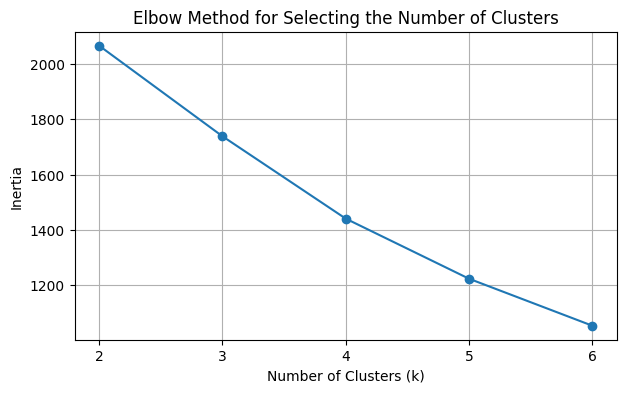

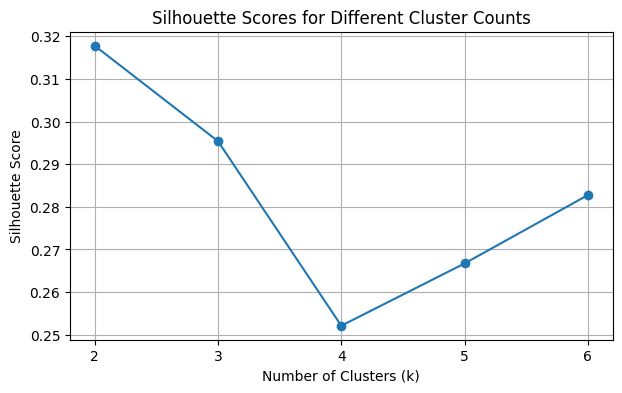

,Number of Clusters,Inertia,Silhouette Score
0,2,2065.061,0.318
1,3,1738.043,0.295
2,4,1440.655,0.252
3,5,1223.683,0.267
4,6,1054.087,0.283


In [7]:
from sklearn.metrics import silhouette_score

k_values = range(2, 7)

inertias = []
silhouette_scores = []

for k in k_values:
    model = KMeans(
        n_clusters = k,
        random_state = 42,
        n_init = 10
    )

    labels = model.fit_predict(x_scaled)

    inertias.append(model.inertia_)
    silhouette_scores.append(
        silhouette_score(x_scaled, labels)
    )

# Plotting the Elbow Method
plt.figure(figsize=(7, 4))
plt.plot(list(k_values), inertias, marker="o")
plt.title("Elbow Method for Selecting the Number of Clusters")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

# Plotting silhouette scores
plt.figure(figsize=(7, 4))
plt.plot(list(k_values), silhouette_scores, marker="o")
plt.title("Silhouette Scores for Different Cluster Counts")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

# Display the results
cluster_scores = pd.DataFrame({
    "Number of Clusters": list(k_values),
    "Inertia": inertias,
    "Silhouette Score": silhouette_scores
})

display(cluster_scores.round(3))

The rough interpretation for the plots above are as follows;
*   Elbow Method - look for the point where the decrease in inertia begins to slow down noticeably. Inertia measures how tightly grouped the data points are within their clusters.
*   Silhouette Score - values closer to 1 generally indicate better-separated, more compact clusteres. Values near 0 suggest overlapping clusters while negative values can indicate poorly assigned observations.



In [8]:
best_k = list(k_values)[np.argmax(silhouette_scores)]

print("Selected number of clusters:", best_k)

# Training the final clustering model
final_model = KMeans(
    n_clusters = best_k,
    random_state = 42,
    n_init = 10
)

clustered_df["Cluster"] = final_model.fit_predict(x_scaled)

print("\nStudents in each cluster:")
print(clustered_df["Cluster"].value_counts().sort_index())

Selected number of clusters: 2

Students in each cluster:
Cluster
0    307
1    342
Name: count, dtype: int64


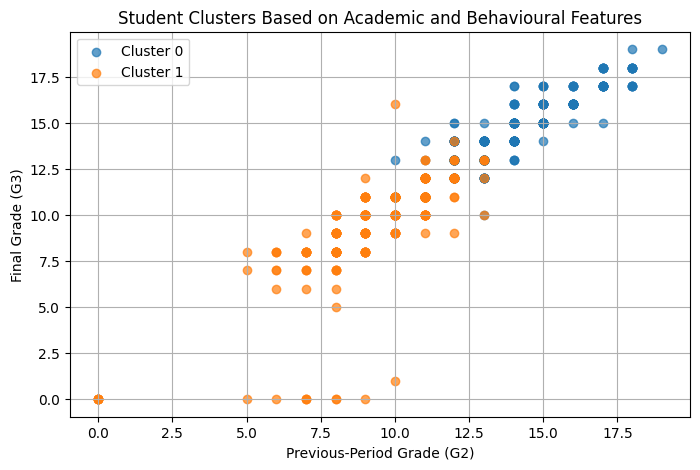

In [9]:
plt.figure(figsize=(8, 5))

for cluster in sorted(clustered_df["Cluster"].unique()):
    group = clustered_df[clustered_df["Cluster"] == cluster]

    plt.scatter(
        group["G2"],
        group["G3"],
        label=f"Cluster {cluster}",
        alpha=0.7
    )

plt.title("Student Clusters Based on Academic and Behavioural Features")
plt.xlabel("Previous-Period Grade (G2)")
plt.ylabel("Final Grade (G3)")
plt.legend()
plt.grid(True)
plt.show()

In [10]:
cluster_profiles = clustered_df.groupby("Cluster")[
    selected_features
].mean().round(2)

print("Average characteristics of each cluster:")
display(cluster_profiles)

print("\nNumber of students in each cluster:")
display(clustered_df.groupby("Cluster").size().rename("Number of Students"))

Average characteristics of each cluster:


,studytime,absences,G1,G2,G3
Cluster,,,,,
0,2.20,2.54,13.62,13.87,14.37
1,1.69,4.66,9.41,9.51,9.69



Number of students in each cluster:


,Number of Students
Cluster,
0,307
1,342


##Discussion and Interpretation
K-Means clustering was applied to the Student Performance dataset using study time, absences, G1, G2, and G3. The features were standardized before clustering to ensure that variables with substantially larger numerical scales did not dominate the distance calculations.

The Elbow Method and Silhouette Score were used to investigate suitable numbers of lcusters. Based on these results, two(2) clusters were selected for further analysis.

The cluster profiles showed differences in academic performance, study time, and school absences. Cluster 0, containing 307 students, had higher average grades with a G1 of 13.62, G2 of 13.87 and G3 of 14.37. It also had a higher average study-time category of 2.20 and fewer absences averaging to 2.54.

On the other hand, Cluster 1 containg 342 students had lower average grades with a G1 of 9.41, G2 of 9.51 and G3 of 9.69. It had a lower average study-time category of 1.69 and more absences averaging to 4.66.

These patterns suggest that Cluster 0 represents a group with relatively higher academic performance while Cluster 1 represents a goup with relatively lower academic performance and more absences.

These findings could help guide further investigation into students that may benefit from additional academic support. However, clustering identifies similarities rather than proving why students perform differently. Thus the results do not establish causation, and the cluster labels do not represent fixed categories of student ability.